<a href="https://colab.research.google.com/github/akhil7981/ML_LAB_2026-27/blob/main/ML3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Sample:
   Size_sqft  Bedrooms  Age     Price
0     2248.0         2   24  280775.0
1     1931.0         2   20  246710.0
2     2324.0         1   35  281532.0
3     2762.0         1   22  317827.0
4     1883.0         1   15  252356.0

--- Model Performance ---
Coefficients (Size, Bedrooms, Age): [   98.46841243 13779.73735476  -886.54680548]
Intercept: 55193.09
Mean Squared Error (MSE): 128563304.07
R-squared Score: 0.9360


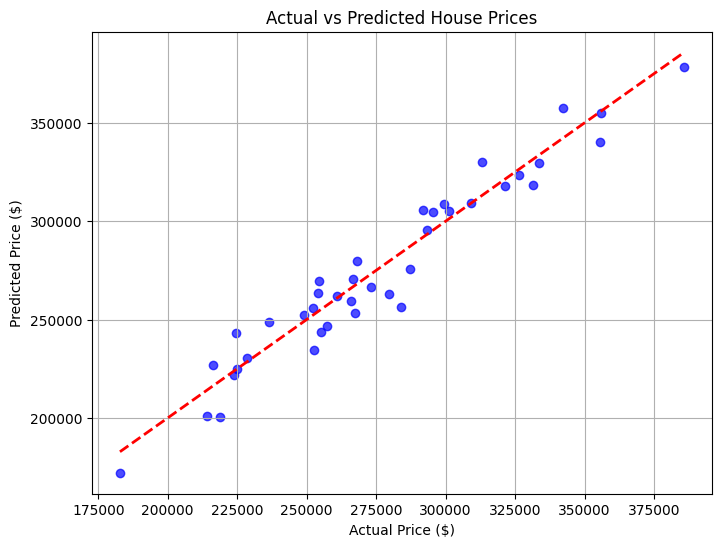

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Generate Synthetic Housing Dataset
# Features: Size (sqft), Number of Bedrooms, Age of House (years)
np.random.seed(42)
n_samples = 200
sizes = np.random.normal(2000, 500, n_samples).round()
bedrooms = np.random.randint(1, 6, n_samples)
ages = np.random.randint(0, 50, n_samples)

# True relationship with some noise
# Price = 100 * Size + 15000 * Bedrooms - 1000 * Age + Noise
noise = np.random.normal(0, 15000, n_samples)
prices = (100 * sizes + 15000 * bedrooms - 1000 * ages + 50000 + noise).round()

# Create a DataFrame
df = pd.DataFrame({
    'Size_sqft': sizes,
    'Bedrooms': bedrooms,
    'Age': ages,
    'Price': prices
})

print("Dataset Sample:")
print(df.head())

# 2. Split Features and Target Variable
X = df[['Size_sqft', 'Bedrooms', 'Age']]
y = df['Price']

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train the Multiple Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Make Predictions
y_pred = model.predict(X_test)

# 5. Evaluate the Model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance ---")
print(f"Coefficients (Size, Bedrooms, Age): {model.coef_}")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score: {r2:.4f}")

# 6. Plot actual vs. predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted House Prices')
plt.grid(True)
plt.show()